In [21]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

data = pd.read_csv("result/flight_data_original.csv")
data_ambient = pd.read_csv("result/flight_data_python_ambient_pressure.csv")
data_adjusted_pressure = pd.read_csv("result/flight_data_python_engine.csv")

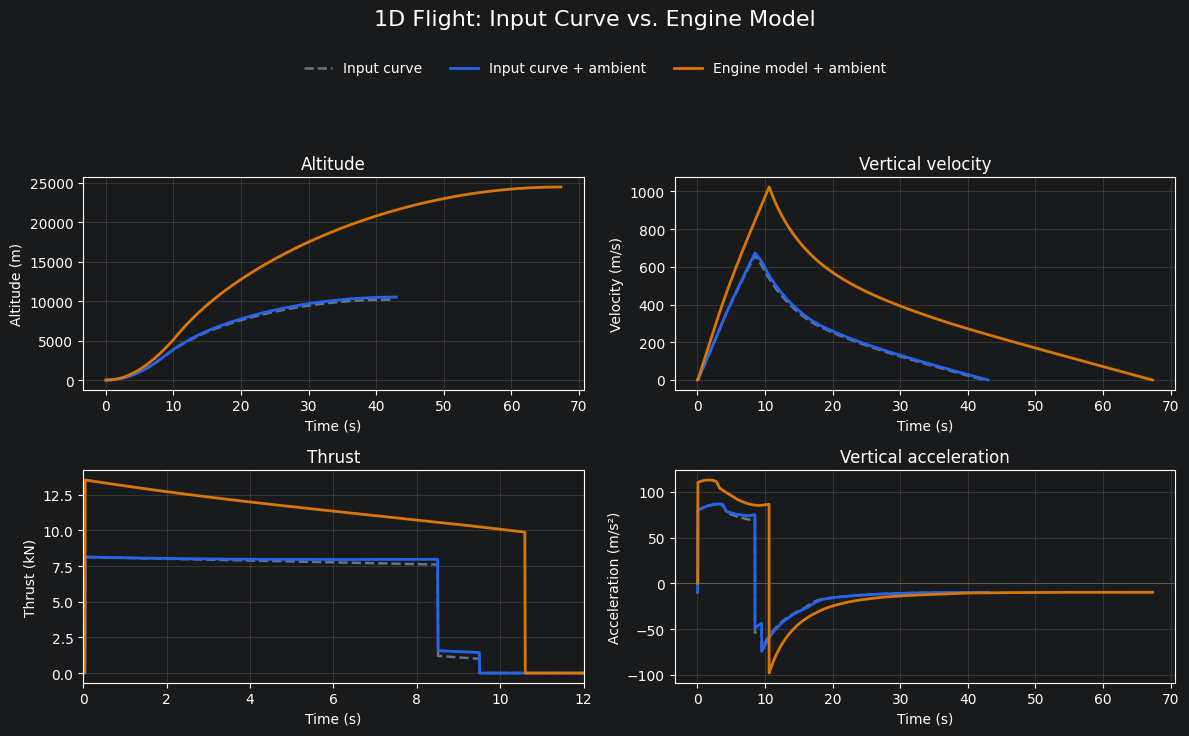

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

baseline = {"color": "#64748b", "linestyle": "--", "linewidth": 1.8}
corrected = {"color": "#2563eb", "linewidth": 2.0}
engine_style = {"color": "#d97706", "linewidth": 2.0}

ax = axes[0, 0]
original_line, = ax.plot(data["time"], data["altitude"], **baseline)
ambient_line, = ax.plot(data_ambient["time"], data_ambient["altitude"], **corrected)
engine_line, = ax.plot(data_adjusted_pressure["time"], data_adjusted_pressure["altitude"], **engine_style)
ax.set(title="Altitude", xlabel="Time (s)", ylabel="Altitude (m)")
ax.grid(alpha=0.25)

ax = axes[0, 1]
ax.plot(data["time"], data["velocity"], **baseline)
ax.plot(data_ambient["time"], data_ambient["velocity"], **corrected)
ax.plot(data_adjusted_pressure["time"], data_adjusted_pressure["velocity"], **engine_style)
ax.set(title="Vertical velocity", xlabel="Time (s)", ylabel="Velocity (m/s)")
ax.grid(alpha=0.25)

ax = axes[1, 0]
ax.plot(data["time"], data["thrust"] / 1000, **baseline)
ax.plot(data_ambient["time"], data_ambient["thrust"] / 1000, **corrected)
ax.plot(data_adjusted_pressure["time"], data_adjusted_pressure["thrust"] / 1000, **engine_style)
ax.set(title="Thrust", xlabel="Time (s)", ylabel="Thrust (kN)", xlim=(0, 12))
ax.grid(alpha=0.25)

ax = axes[1, 1]
ax.plot(data["time"], data["acceleration"], **baseline)
ax.plot(data_ambient["time"], data_ambient["acceleration"], **corrected)
ax.plot(data_adjusted_pressure["time"], data_adjusted_pressure["acceleration"], **engine_style)
ax.axhline(0, color="gray", linewidth=0.8, alpha=0.5)
ax.set(title="Vertical acceleration", xlabel="Time (s)", ylabel="Acceleration (m/s²)")
ax.grid(alpha=0.25)

fig.suptitle("1D Flight: Input Curve vs. Engine Model", fontsize=16, y=0.98)
fig.legend(
    [original_line, ambient_line, engine_line],
    ["Input curve", "Input curve + ambient", "Engine model + ambient"],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=3,
    frameon=False,
)

fig.tight_layout(rect=(0, 0.065, 1, 0.86))
plt.show()